In [ ]:

!pip install -q ultralytics huggingface_hub opencv-python


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 7.7 MB/s eta 0:00:00


In [ ]:

from huggingface_hub import hf_hub_download
from ultralytics import YOLO

# 1. 이미 학습된 번호판 탐지 모델 다운로드
model_path = hf_hub_download(
    repo_id="Koushim/yolov8-license-plate-detection",
    filename="best.pt"
)

# 2. 다운로드한 AI 모델 불러오기
model = YOLO(model_path)

# 3. 성공 여부 확인
print("번호판 AI 모델 불러오기 성공!")
print("모델 위치:", model_path)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


best.pt: reconstructing file:   0%|          |  0.00B / 6.25MB            

best.pt: downloading bytes:           |  0.00B            

번호판 AI 모델 불러오기 성공!
모델 위치: /root/.cache/huggingface/hub/models--Koushim--yolov8-license-plate-detection/snapshots/9aaa5cd490abe0c165882ba87f4f62658ab54d01/best.pt


Saving 차.png to 차.png

image 1/1 /content/차.png: 448x640 1 license_plate, 412.5ms
Speed: 26.1ms preprocess, 412.5ms inference, 37.0ms postprocess per image at shape (1, 3, 448, 640)
AI가 찾은 번호판: 1개


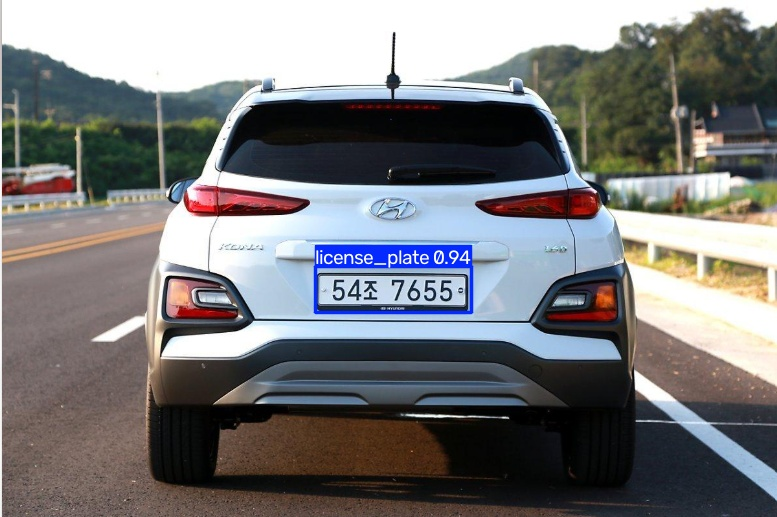

In [ ]:

from google.colab import files
from IPython.display import display, Image

# 1. 분석할 자동차 사진 선택
uploaded = files.upload()

# 2. 업로드한 사진 이름 가져오기
image_path = next(iter(uploaded))

# 3. AI에게 번호판을 찾아달라고 요청
results = model.predict(
    source=image_path,
    conf=0.25,
    save=False
)

# 4. 번호판을 찾은 개수 확인
count = len(results[0].boxes)
print(f"AI가 찾은 번호판: {count}개")

# 5. 번호판 위치에 네모 박스 표시
output_path = "plate_detected.jpg"
results[0].save(filename=output_path)

# 6. 결과 이미지 보여주기
display(Image(filename=output_path))


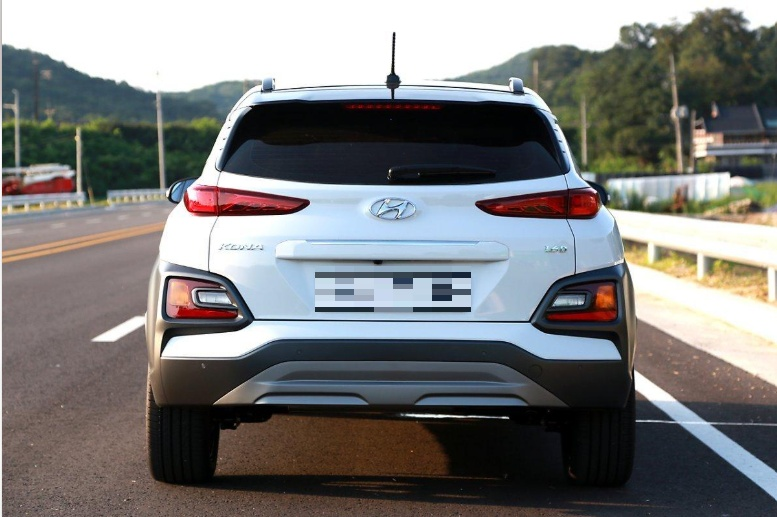

번호판 모자이크 완료!


In [ ]:

import cv2
from IPython.display import display, Image

# 1. 원본 사진 불러오기
image = cv2.imread(image_path)

# 2. AI가 찾은 번호판 위치 가져오기
boxes = results[0].boxes.xyxy.cpu().numpy()

# 3. 번호판 부분에 모자이크 적용
for box in boxes:
    x1, y1, x2, y2 = map(int, box)

    # 번호판 부분만 잘라내기
    plate = image[y1:y2, x1:x2]

    if plate.size == 0:
        continue

    # 번호판을 작게 줄였다가 다시 확대
    small = cv2.resize(plate, (8, 8))
    mosaic = cv2.resize(
        small,
        (x2-x1, y2-y1),
        interpolation=cv2.INTER_NEAREST
    )

    # 모자이크한 부분을 원본 사진에 붙이기
    image[y1:y2, x1:x2] = mosaic

# 4. 결과 사진 저장
cv2.imwrite("avly_mosaic.jpg", image)

# 5. 모자이크 결과 보여주기
display(Image(filename="avly_mosaic.jpg"))

print("번호판 모자이크 완료!")


- 블랙박스 영상 번호판 모자이크

In [ ]:

from google.colab import files

# 블랙박스 영상 업로드
uploaded_video = files.upload()

# 업로드한 영상 파일 이름 저장
video_path = next(iter(uploaded_video))

print("영상 업로드 성공!")
print("파일 이름:", video_path)


Saving bb_1_130212_vehicle_250_21680.mp4 to bb_1_130212_vehicle_250_21680.mp4
영상 업로드 성공!
파일 이름: bb_1_130212_vehicle_250_21680.mp4


In [ ]:

import cv2

# 영상 파일 열기
video = cv2.VideoCapture(video_path)

# 영상이 정상적으로 열렸는지 확인
if video.isOpened():
    print("영상 열기 성공!")

    # 영상 정보 확인
    fps = video.get(cv2.CAP_PROP_FPS)
    frame_count = video.get(cv2.CAP_PROP_FRAME_COUNT)

    if fps > 0:
        duration = frame_count / fps
        print(f"영상 길이: {duration:.1f}초")
        print(f"초당 프레임 수: {fps:.1f}")
        print(f"전체 프레임 수: {int(frame_count)}")
    else:
        print("영상의 프레임 정보를 확인할 수 없습니다.")

else:
    print("영상 열기 실패!")

video.release()


영상 열기 성공!
영상 길이: 10.0초
초당 프레임 수: 15.0
전체 프레임 수: 150


In [ ]:

import cv2
from IPython.display import display, Video

# 1. 원본 영상 열기
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# 2. 결과 영상을 저장할 준비
output_path = "avly_mosaic_video.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter(
    output_path, fourcc, fps, (width, height)
)

# 3. 영상의 각 프레임을 하나씩 처리
frame_number = 0
detected_frames = 0

while True:
    ret, frame = cap.read()

    # 더 이상 읽을 프레임이 없으면 종료
    if not ret:
        break

    # 4. YOLO로 번호판 찾기
    results = model.predict(
        source=frame,
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes.xyxy.cpu().numpy()

    if len(boxes) > 0:
        detected_frames += 1

    # 5. 찾은 번호판을 검은색으로 가리기
    for box in boxes:
        x1, y1, x2, y2 = map(int, box)

        # 번호판 주변을 조금 더 넓게 가리기
        margin = 5
        x1 = max(0, x1 - margin)
        y1 = max(0, y1 - margin)
        x2 = min(width, x2 + margin)
        y2 = min(height, y2 + margin)

        cv2.rectangle(
            frame, (x1, y1), (x2, y2),
            (0, 0, 0), -1
        )

    # 6. 처리한 프레임 저장
    out.write(frame)
    frame_number += 1

# 7. 영상 파일 닫기
cap.release()
out.release()

print("영상 처리 완료!")
print("전체 처리 프레임:", frame_number)
print("번호판 탐지 프레임:", detected_frames)
print("저장 파일:", output_path)


영상 처리 완료!
전체 처리 프레임: 150
번호판 탐지 프레임: 99
저장 파일: avly_mosaic_video.mp4


In [ ]:

import subprocess
from IPython.display import Video, display

# 1. 브라우저에서 재생하기 좋은 영상으로 변환
subprocess.run([
    "ffmpeg", "-y",
    "-i", "avly_mosaic_video.mp4",
    "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "avly_mosaic_play.mp4"
], check=True, capture_output=True)

# 2. 결과 영상 재생하기
display(Video(
    "avly_mosaic_play.mp4",
    embed=True,
    width=640
))

print("영상 재생 준비 완료!")


영상 재생 준비 완료!


In [ ]:

from google.colab import files

files.download("avly_mosaic_play.mp4")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>